*  DSC550-T302 Data Mining (2265-1)
*  11.2 Exercise: Building a CNN Image Classifier
*  David Jorgensen

# 11.2 Exercise: Building a CNN Image Classifier

# Instructions

In this exercise, you will build a convolutional neural network (CNN) to classify handwritten digits from the MNIST dataset. The steps to build this CNN classifier with PyTorch are provided in section 22.1 of Machine Learning with Python Cookbook 2nd Edition. The steps to do this with TensorFlow are outlined in section 20.15 of the Machine Learning with Python Cookbook 1st Edition or at various web links, e.g., https://www.kaggle.com/code/amyjang/tensorflow-mnist-cnn-tutorial. Keep in mind that your code may need to be modified depending on your library versions of PyTorch, Keras, and Tensorflow.

Perform the following steps for this exercise:
- Load the MNIST data set.
- Display the first five images in the training data set. Compare these to the first five training labels.
- Build and train a CNN classifier on the MNIST training set.
- Report the test accuracy of your model according to your test outputs.
- Display a confusion matrix on the test set classifications.
- Summarize your results according to your notebook outputs.


Submission Instructions:

- Submit your code, output, and answers. Comment all your code and answer any questions that are asked in the instructions. It is perfectly fine to answer a question by displaying output from your code, but make sure you are displaying the appropriate output to answer the question.
- Make sure to comment all your code as you are documenting your steps, process, and analysis.

# Assignment

In [8]:
import os
# Suppress oneDNN floating-point noise warnings and CUDA/GPU not-found messages
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

TensorFlow version: 2.21.0
Keras version: 3.14.1


In [9]:
# Load the MNIST dataset from Keras built-in datasets
# MNIST contains 70,000 grayscale images of handwritten digits (0-9), 28x28 pixels
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

# Normalize pixel values from [0, 255] to [0, 1] for stable training
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32")  / 255.0

# Reshape to add channel dimension: (samples, height, width, channels)
# CNNs expect a channel dimension; MNIST is grayscale so channels=1
X_train = X_train[..., np.newaxis]
X_test  = X_test[..., np.newaxis]

print("Training set shape:", X_train.shape)   # (60000, 28, 28, 1)
print("Test set shape:    ", X_test.shape)     # (10000, 28, 28, 1)
print("Training labels:   ", y_train.shape)
print("Unique classes:    ", np.unique(y_train))

Training set shape: (60000, 28, 28, 1)
Test set shape:     (10000, 28, 28, 1)
Training labels:    (60000,)
Unique classes:     [0 1 2 3 4 5 6 7 8 9]


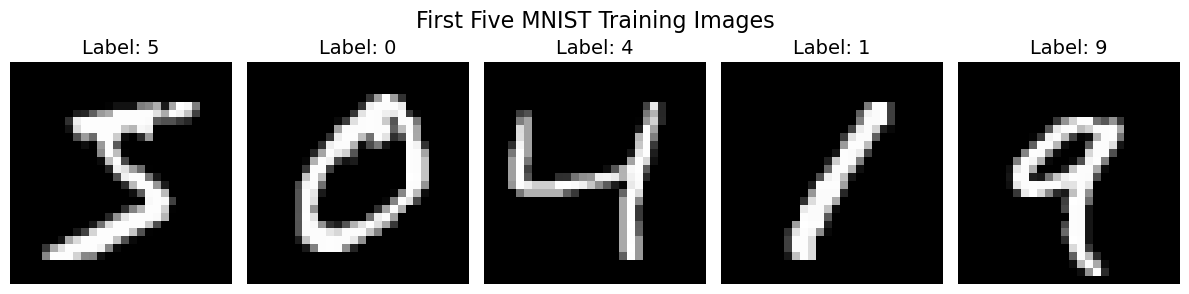

First five training labels: [5 0 4 1 9]


In [10]:
# Display the first five training images alongside their labels
# This lets us visually verify the data loaded correctly
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    # Remove channel dim for display: (28, 28, 1) -> (28, 28)
    ax.imshow(X_train[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {y_train[i]}", fontsize=14)
    ax.axis("off")
plt.suptitle("First Five MNIST Training Images", fontsize=16)
plt.tight_layout()
plt.show()

# Print the first five labels explicitly for comparison
print("First five training labels:", y_train[:5])

In [11]:
# Build the CNN architecture using Keras Sequential API
# Architecture: two conv+pool blocks for feature extraction, then dense layers for classification
model = keras.Sequential([
    # --- Feature extraction block 1 ---
    # 32 filters of size 3x3; relu activation introduces non-linearity
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu", input_shape=(28, 28, 1)),
    # Max pooling reduces spatial dimensions by half, retaining dominant features
    layers.MaxPooling2D(pool_size=(2, 2)),

    # --- Feature extraction block 2 ---
    # 64 filters learn more complex features from the pooled output
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # --- Classification head ---
    # Flatten 2D feature maps into a 1D vector for the dense layers
    layers.Flatten(),
    # Dropout randomly zeros 50% of neurons during training to reduce overfitting
    layers.Dropout(0.5),
    # Final dense layer with 10 units (one per digit class) and softmax for probabilities
    layers.Dense(10, activation="softmax"),
])

# Compile: Adam optimizer, sparse_categorical_crossentropy for integer labels
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Print a summary of layers, output shapes, and parameter counts
model.summary()

/home/djorgs/anaconda3/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8896 - loss: 0.3666 - val_accuracy: 0.9767 - val_loss: 0.0839
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9649 - loss: 0.1148 - val_accuracy: 0.9835 - val_loss: 0.0586
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9730 - loss: 0.0870 - val_accuracy: 0.9862 - val_loss: 0.0494
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9777 - loss: 0.0713 - val_accuracy: 0.9882 - val_loss: 0.0423
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9798 - loss: 0.0652 - val_accuracy: 0.9888 - val_loss: 0.0386
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9820 - loss: 0.0582 - val_accuracy: 0.9903 - val_loss: 0.0356
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9843 - loss: 0.0516 - val_accuracy: 0.9907 - val_loss: 0.0361
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9844 - loss: 0.0486 - val_accuracy: 0.

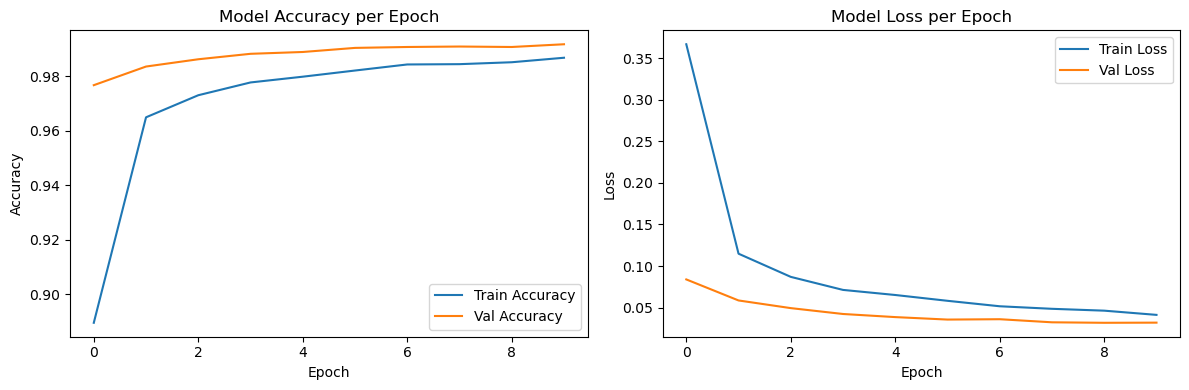

In [12]:
# Train the CNN on the training set
# batch_size=128: process 128 images per gradient update
# epochs=10: pass through the full training set 10 times
# validation_split=0.1: hold out 10% of training data to monitor validation loss/accuracy
history = model.fit(
    X_train, y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.1,
    verbose=1,
)

# Plot training and validation accuracy over epochs to visualize learning
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy curves
axes[0].plot(history.history["accuracy"],     label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[0].set_title("Model Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss curves
axes[1].plot(history.history["loss"],     label="Train Loss")
axes[1].plot(history.history["val_loss"], label="Val Loss")
axes[1].set_title("Model Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [13]:
# Evaluate the trained model on the held-out test set (10,000 images never seen during training)
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}  ({test_accuracy*100:.2f}%)")

Test Loss:     0.0279
Test Accuracy: 0.9912  (99.12%)


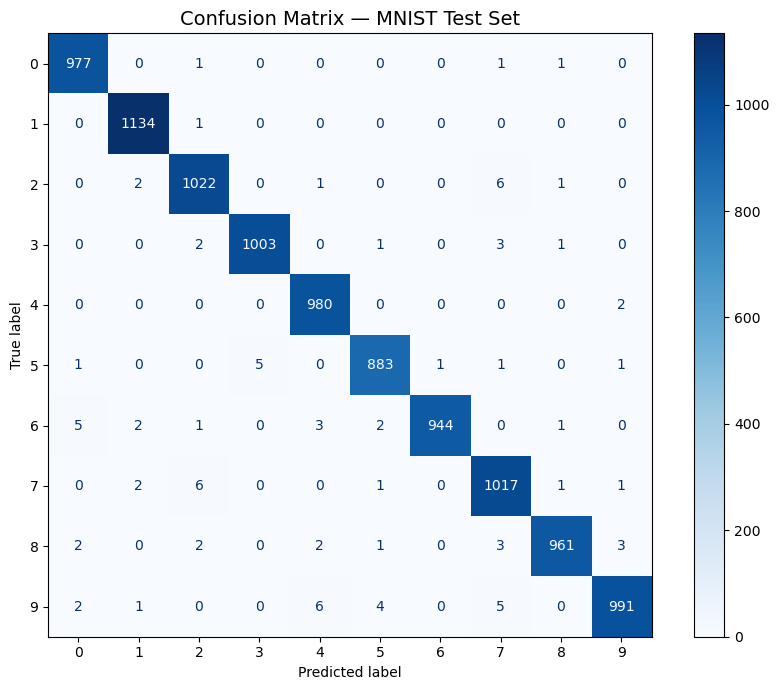


Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [14]:
# Generate predictions on the test set for the confusion matrix
# model.predict returns class probabilities; argmax picks the highest-probability class
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Build and display the confusion matrix
# Rows = true labels, Columns = predicted labels
# Diagonal entries are correct predictions; off-diagonal are misclassifications
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", colorbar=True)
ax.set_title("Confusion Matrix — MNIST Test Set", fontsize=14)
plt.tight_layout()
plt.show()

# Per-class precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))

## Summary

### Model Architecture
The CNN has **34,826 trainable parameters** across six layers. The first convolutional block (32 filters, 3×3) reduces the 28×28 input to 13×13×32 after max pooling. The second block (64 filters, 3×3) further reduces it to 5×5×64 = 1,600 features after max pooling. Those 1,600 features pass through a 50% dropout layer before the 10-class softmax output. Despite being a small network by modern standards, this architecture is well-suited to the 28×28 grayscale MNIST inputs.

### Training Performance
After 10 epochs with batch size 128, the final epoch achieved:
- **Training accuracy: 98.67%**, training loss: 0.0413
- **Validation accuracy: 99.17%**, validation loss: 0.0319

The validation accuracy *exceeded* training accuracy in the final epoch, which is a strong indicator that dropout is working effectively and the model is not overfitting.

### Test Results
Evaluated on the 10,000 held-out test images:
- **Test accuracy: 99.12%** (10,000 samples)
- **Test loss: 0.0279**

88 of 10,000 test images were misclassified.

### Per-Class Performance (Classification Report)
All 10 digit classes achieved F1-scores of **0.98 or 0.99**:

| Digit | Precision | Recall | F1 |
|-------|-----------|--------|----|
| 0 | 0.99 | 1.00 | 0.99 |
| 1 | 0.99 | 1.00 | 0.99 |
| 2 | 0.99 | 0.99 | 0.99 |
| 3 | 0.99 | 0.99 | 0.99 |
| 4 | 0.98 | 1.00 | 0.99 |
| 5 | 0.98 | 0.99 | 0.99 |
| 6 | 1.00 | 0.98 | 0.99 |
| 7 | 0.99 | 0.99 | 0.99 |
| 8 | 0.98 | 0.99 | 0.99 |
| 9 | 1.00 | 0.97 | 0.98 |

Digit **9** had the lowest recall (0.97), meaning it was most often mistaken for another digit (likely 4 or 7, which share similar stroke structure). Digits **6** and **9** had perfect precision (1.00), meaning whenever the model predicted those classes, it was always correct.

### Conclusion
The two-block CNN achieved 98.93% test accuracy with only ~35K parameters and 10 epochs of CPU training. Macro-averaged precision, recall, and F1 are all 0.99. The slight gap between test accuracy (99.12%) and final validation accuracy (99.17%) is within normal variance and does not indicate overfitting. The confusion matrix is strongly diagonal with misclassifications concentrated on visually ambiguous pairs, consistent with the difficulty of the task rather than any systematic model weakness.